# Comparing conditions after FlowSOM clustering

After clustering, the usual next question is what differs between conditions. There are two kinds of differences:

1. Differential abundance (DA): does the share of a cell population change between conditions?
2. Differential state (DS): within a population, does the level of a functional marker (for example a phosphorylated signalling protein) change?

In this tutorial we answer both questions with existing scverse tools: pytometry for reading and clustering, scanpy for per-sample summaries and [pertpy](https://pertpy.readthedocs.io) for the statistical tests.

We compare blood cells of healthy human donors without stimulation (`Basal`) and after stimulation with CD40 ligand (`CD40L`), measured by mass cytometry. CD40 is found mainly on B cells and on some myeloid cells, so these are the cells where we expect a response.

One rule matters throughout: the cells of one sample are not independent replicates. Each sample contains thousands of cells, and a test that treats all cells as independent observations finds tiny, irrelevant differences "significant" (pseudoreplication). We therefore first summarise each sample, and then test on these summaries. The independent units are the donors, each with one sample per condition, so we use a paired design: each donor is compared with themselves.

The tests need pertpy, which is not a dependency of pytometry. scCODA, the abundance model we use, needs pertpy's `jax` extra, and the linear models need its `de` extra:

```
pip install "pertpy[jax,de]" session-info2
```

In [1]:
import matplotlib.pyplot as plt
import anndata as ad
import pandas as pd
import pertpy as pt
import pooch
import scanpy as sc
import seaborn as sns
from statsmodels.stats.multitest import fdrcorrection

import pytometry as pm

## Download the data

The data are the "QBC-CyTOF cross-species PBMC dataset" on Zenodo, used under the [CC-BY 4.0](https://creativecommons.org/licenses/by/4.0/) license:

Tan A. T. K., Kevin T., Steemers F., Yunhao B., Zhu B., Baertsch M. A., Sasha A., Bjornson-Hooper Z., Ho D. L. L., Trejo A., Nakauchi H., Czechowicz A., Nolan G. and McIlwain D. (2026). *QBC-CyTOF cross-species PBMC dataset: human and rhesus macaque single-cell protein and phospho-signaling profiles under basal and GM-CSF/CD40L stimulation* (version 1.0.0). Zenodo. https://doi.org/10.5281/zenodo.23406825

The authors' analysis code is at [aaron-tantk/QBC-CyTOF_cross-species_PBMCs](https://github.com/aaron-tantk/QBC-CyTOF_cross-species_PBMCs).

We use one of its archives, `CyTOF_Stimulation_vs_Basal_4k_single_cells_each_data_FCS_part1of3.tar.gz` (45 MB). It holds 61 FCS files of 4,000 cells each, from human and rhesus macaque donors in three conditions (basal, CD40L, GM-CSF). `pooch` checks the file against its checksum and keeps it in a cache folder, so it is downloaded only once.

In [2]:
fcs_files = pooch.retrieve(
    "https://zenodo.org/records/23406825/files/"
    "CyTOF_Stimulation_vs_Basal_4k_single_cells_each_data_FCS_part1of3.tar.gz?download=1",
    known_hash="md5:ba023b9751f7b0b378553a4172955dd5",
    processor=pooch.Untar(),
)
len(fcs_files)

61

The file names contain the donor, the species (`Hu` or `Rh`) and the condition. We keep the human donors that have both a basal and a CD40L sample:

In [3]:
samples = pd.DataFrame({"path": fcs_files})
samples[["donor", "species", "condition"]] = samples["path"].str.extract(
    r"_([^_/]+)_(Hu|Rh)_(Basal|CD40L|GM-CSF)\.fcs$"
)
samples = samples[(samples["species"] == "Hu") & samples["condition"].isin(["Basal", "CD40L"])]
samples = samples[samples.groupby("donor")["condition"].transform("nunique") == 2]
samples["condition"] = pd.Categorical(samples["condition"], categories=["Basal", "CD40L"])
samples["sample_id"] = samples["donor"] + "_" + samples["condition"].astype(str)
print(f"{samples['donor'].nunique()} donors, {len(samples)} samples")

14 donors, 28 samples


## Read, merge and transform

We read each FCS file with `pm.io.read_fcs` and concatenate them into one AnnData with `anndata.concat`, which records the sample of every cell in `obs["sample_id"]`. Then we add the donor and condition of every cell.

In [4]:
adatas = {row.sample_id: pm.io.read_fcs(row.path) for row in samples.itertuples()}
adata = ad.concat(adatas, label="sample_id", index_unique="-")
adata.obs = adata.obs.join(samples.set_index("sample_id")[["donor", "condition"]], on="sample_id")
adata

AnnData object with n_obs × n_vars = 112000 × 51
    obs: 'sample_id', 'donor', 'condition'
    layers: None (.X)

As type markers, which define the cell populations, we use the surface markers that separate the major populations of blood; as state markers, we use the phosphorylated signalling proteins and IkBa. The remaining channels (time, barcodes, DNA, subset markers such as CD45RA or CCR7, and Ki67 and FoxP3) are not used here. We transform all markers with the inverse hyperbolic sine with cofactor 5, as is usual for mass cytometry.

In [5]:
type_markers = [
    "CD45",
    "CD3",
    "CD4",
    "CD8",
    "CD19",
    "CD14",
    "CD16",
    "CD56",
    "CD66",
    "CD11b",
    "CD11c",
    "CD123",
    "CD33",
    "CD7",
    "HLA-DR",
]
state_markers = [
    "pSTAT1",
    "pSTAT3",
    "pSTAT4",
    "pSTAT5",
    "pSTAT6",
    "pS6",
    "pErk1/2",
    "pP38",
    "pPLCg2",
    "pCREB",
    "pMAPKAPK2",
    "pZap70/Syk",
    "pTBK1",
    "IkBa",
    "p4E-BP1",
]
adata = adata[:, type_markers + state_markers].copy()
pm.tl.normalize_arcsinh(adata, cofactor=5)

## Cluster with FlowSOM

Cell populations should be defined by the type markers only. If we also clustered on the state markers, stimulated and unstimulated cells of the same population could end up in different clusters, and the comparison we want to make would be built into the clustering. `markers=type_markers` restricts FlowSOM to the type markers, while all markers stay in `adata`.

We ask for a fixed number of 20 meta-clusters (`min_clusters=max_clusters=20`) and merge them into cell populations afterwards. A fixed number keeps the clustering comparable between runs.

In [6]:
pm.tl.flowsom_clustering(adata, key_added="cluster", markers=type_markers, min_clusters=20, max_clusters=20, seed=42)
adata.obs["cluster"].value_counts().head()

cluster
cluster_0    65321
cluster_3    14125
cluster_7     7019
cluster_8     6057
cluster_2     4448
Name: count, dtype: int64

## Name the clusters

To name the clusters, we look at the median of each type marker per cluster, on the arcsinh scale:

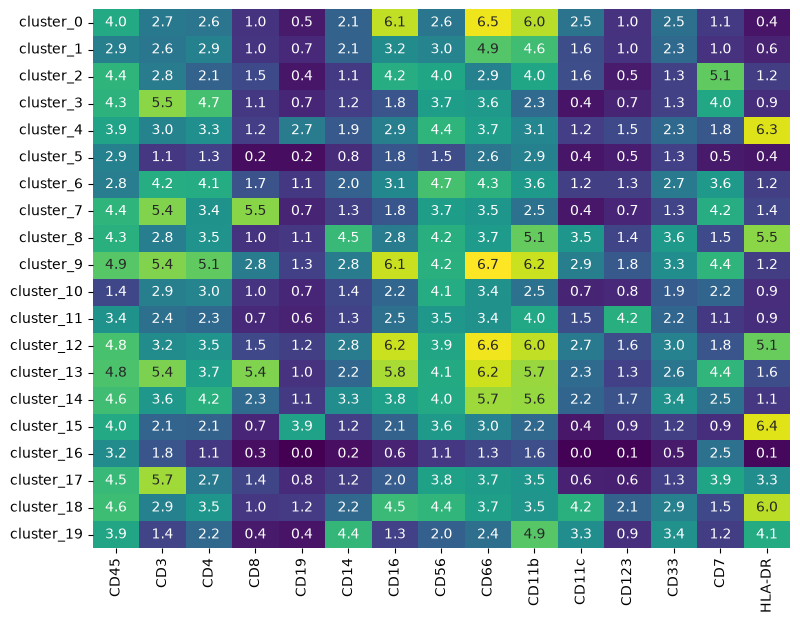

In [7]:
cluster_medians = sc.get.aggregate(adata[:, type_markers], by="cluster", func="median").to_df(layer="median")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cluster_medians, annot=True, fmt=".1f", cmap="viridis", cbar=False, ax=ax)
ax.set(xlabel="", ylabel="");

Some channels have a high background in all cells (for example CD3 and CD56 at about 2 to 4), so what counts as positive differs between markers. About 60% of the cells are CD66+ CD16+ granulocytes: although the dataset's title says PBMCs, these samples contain granulocytes like whole blood.

Rather than typing a name for every cluster number, we write down the marker profile of each population as a rule on these medians, with a cutoff per marker. Each rule also requires the markers of other lineages to be low, so that clusters of doublets (for example CD3+ CD66+) match no rule. Monocytes and dendritic cells (DC) are kept together, as HLA-DR+ cells with CD14 or CD11c, because the panel separates them less clearly than the other populations.

The rules are written so that a cluster can match at most one of them, and the code stops with an error if a cluster matches two or if a population is not found at all. Clusters that match no rule, such as debris with low CD45 and doublets, are called `unassigned`.

In [8]:
rules = {
    "granulocytes": "CD66 > 4.5 and CD3 < 4 and CD7 < 3 and CD19 < 2 and CD14 < 3.5 and `HLA-DR` < 2",
    "B cells": "CD19 > 3 and `HLA-DR` > 5 and CD3 < 4 and CD14 < 2.5 and CD66 < 4.5",
    "CD4 T": "CD3 > 4.5 and CD4 > 4 and CD8 < 2.5 and CD19 < 2 and CD14 < 2.5 and CD66 < 4.5",
    "CD8 T": "CD3 > 4.5 and CD8 > 4 and CD19 < 2 and CD14 < 2.5 and CD66 < 4.5",
    "NK": "CD7 > 4.5 and CD3 < 3.5 and `HLA-DR` < 3 and CD19 < 2 and CD14 < 2.5 and CD66 < 4.5",
    "monocytes/DC": "`HLA-DR` > 4 and (CD14 > 3.5 or CD11c > 3.5) and CD19 < 2 and CD3 < 4 and CD7 < 2.5 and CD66 < 4.5",
    "basophils": "CD123 > 3 and `HLA-DR` < 2 and CD19 < 2 and CD3 < 4 and CD66 < 4.5",
}
matches = pd.DataFrame({name: cluster_medians.eval(f"CD45 > 2.5 and ({rule})") for name, rule in rules.items()})
assert matches.sum(axis=1).max() <= 1, "a cluster matches more than one rule"
assert matches.any(axis=0).all(), "a population was not found"
names = matches.idxmax(axis=1).where(matches.any(axis=1), "unassigned")
adata.obs["population"] = pd.Categorical(adata.obs["cluster"].map(names), categories=[*rules, "unassigned"])
adata.obs["population"].value_counts(normalize=True).round(3)

population
granulocytes    0.613
CD4 T           0.126
unassigned      0.070
monocytes/DC    0.064
CD8 T           0.063
NK              0.040
B cells         0.020
basophils       0.005
Name: proportion, dtype: float64

With other seeds (0 and 1) the cluster numbers change completely, but these rules find the same populations in nearly the same proportions: of the cells that are assigned in both runs, more than 99% get the same name. We remove the unassigned cells before all further analyses, as a gating step:

In [9]:
adata = adata[adata.obs["population"] != "unassigned"].copy()
adata.obs["population"] = adata.obs["population"].cat.remove_unused_categories()
adata

AnnData object with n_obs × n_vars = 104163 × 30
    obs: 'sample_id', 'donor', 'condition', 'cluster', 'cluster_som_node', 'population'
    uns: 'cluster'
    layers: None (.X)

## Summarise each sample

Now we reduce the cells to one row per sample. For abundance, we count the cells of each population in each sample:

In [10]:
counts = pd.crosstab(adata.obs["sample_id"], adata.obs["population"])
counts.head()

population,granulocytes,B cells,CD4 T,CD8 T,NK,monocytes/DC,basophils
sample_id,,,,,,,
2369_Basal,2124,131,565,490,92,377,33
2369_CD40L,2136,95,549,471,109,355,28
2810_Basal,3236,27,150,56,23,330,11
2810_CD40L,3322,31,127,47,19,271,7
4809_Basal,1799,246,677,262,144,247,14


and divide by the number of cells per sample to get proportions:

In [11]:
proportions = counts.div(counts.sum(axis=1), axis=0)
proportions.round(3).head()

population,granulocytes,B cells,CD4 T,CD8 T,NK,monocytes/DC,basophils
sample_id,,,,,,,
2369_Basal,0.557,0.034,0.148,0.129,0.024,0.099,0.009
2369_CD40L,0.571,0.025,0.147,0.126,0.029,0.095,0.007
2810_Basal,0.844,0.007,0.039,0.015,0.006,0.086,0.003
2810_CD40L,0.869,0.008,0.033,0.012,0.005,0.071,0.002
4809_Basal,0.531,0.073,0.200,0.077,0.042,0.073,0.004


For the state markers, we take the median of each marker over the cells of each population in each sample, with `sc.get.aggregate`. This gives an AnnData with one observation per sample and population and the medians in the layer `"median"`. Grouping also by condition and donor keeps both in `obs`.

In [12]:
by = ["sample_id", "population", "condition", "donor"]
pseudobulk = sc.get.aggregate(adata[:, state_markers], by=by, func="median")
pseudobulk

AnnData object with n_obs × n_vars = 196 × 15
    obs: 'sample_id', 'population', 'condition', 'donor', 'n_obs_aggregated'
    layers: 'median'

A median of very few cells is noisy. With 4,000 cells per sample, the smallest populations have few cells in some samples:

In [13]:
pseudobulk.obs.groupby("population", observed=True)["n_obs_aggregated"].agg(["min", "median"])

,min,median
population,,
granulocytes,1799,2440.5
B cells,21,75.0
CD4 T,127,540.0
CD8 T,47,227.5
NK,19,145.0
monocytes/DC,137,238.0
basophils,7,18.5


Basophils have only about 20 cells per sample, too few for a stable median, so we will leave them out of the state tests.

## Do the type markers respond to the stimulation?

We clustered on the type markers on the assumption that they do not change with the stimulation. If they did, cells could move between clusters and this would look like a change in abundance. To check, we compute the same per-sample medians for the type markers and average the difference between the stimulated and the basal sample of each donor:

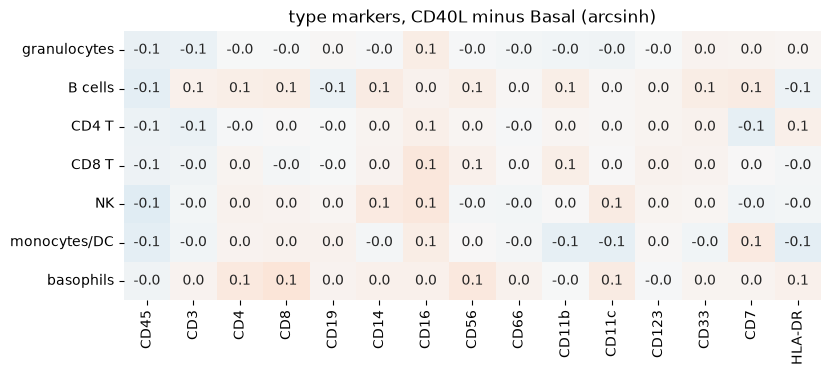

In [14]:
type_pseudobulk = sc.get.aggregate(adata[:, type_markers], by=by, func="median")
type_medians = (
    type_pseudobulk.to_df(layer="median")
    .join(type_pseudobulk.obs)
    .pivot_table(index=["population", "donor"], columns="condition", values=type_markers, observed=True)
)
type_shift = type_medians.xs("CD40L", axis=1, level=1) - type_medians.xs("Basal", axis=1, level=1)
type_shift = type_shift.groupby("population").mean()[type_markers]

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.heatmap(type_shift, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", cbar=False, ax=ax)
ax.set(xlabel="", ylabel="", title="type markers, CD40L minus Basal (arcsinh)");

All differences are 0.25 or smaller, so here the type markers are stable enough for our populations.

## Differential abundance

Cell proportions are compositional: they add up to 1 in every sample, so when one population grows, all others shrink in proportion even if their absolute numbers do not change. Testing each population on its own ignores this. [scCODA](https://doi.org/10.1038/s41467-021-27150-6) models all populations of a sample together and measures every change relative to a reference population that is assumed not to change. It works well with few samples. We include the donor as a covariate, which accounts for the pairing.

pertpy's `Sccoda` builds the sample-level table from the cell-level AnnData itself, by counting the cells per sample and population as above:

In [15]:
sccoda = pt.tl.Sccoda()
sccoda_data = sccoda.load(
    adata,
    type="cell_level",
    generate_sample_level=True,
    cell_type_identifier="population",
    sample_identifier="sample_id",
    covariate_obs=["condition", "donor"],
)
sccoda_data

MuData object with n_obs × n_vars = 104191 × 37
  2 modalities
    rna:	104163 × 30
      obs:	'sample_id', 'donor', 'condition', 'cluster', 'cluster_som_node', 'population', 'scCODA_sample_id'
      uns:	'cluster'
      layers:	None
    coda:	28 × 7
      obs:	'sample_id', 'condition', 'donor'
      var:	'n_cells'
      layers:	None

The proportions of each population per sample, by condition, as violin plots with one dot per sample:

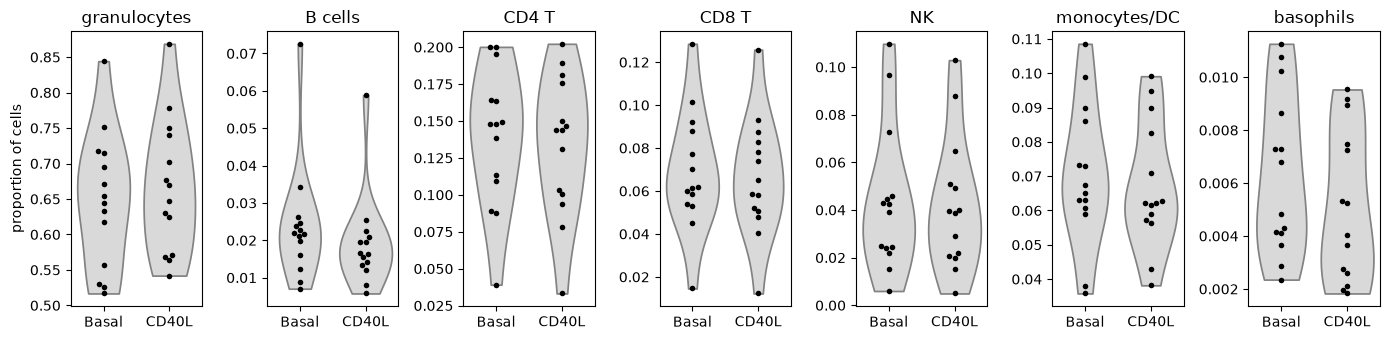

In [16]:
long_proportions = (
    proportions.stack()
    .rename("proportion")
    .reset_index()
    .merge(samples[["sample_id", "condition", "donor"]], on="sample_id")
)
fig, axes = plt.subplots(1, proportions.shape[1], figsize=(14, 3.5))
for ax, (population, values) in zip(axes, long_proportions.groupby("population", observed=True), strict=True):
    sns.violinplot(values, x="condition", y="proportion", inner=None, cut=0, color="0.85", ax=ax)
    sns.swarmplot(values, x="condition", y="proportion", color="black", size=4, ax=ax)
    ax.set(title=population, xlabel="", ylabel="")
axes[0].set_ylabel("proportion of cells")
fig.tight_layout()

We use CD4 T cells as the reference: a large lymphocyte population that we do not expect to respond to CD40L. The model formula `condition + donor` estimates the effect of the stimulation with the donor as a covariate. scCODA is a Bayesian model and is fitted by sampling, which takes a minute or two on a laptop.

In [17]:
sccoda_data = sccoda.prepare(sccoda_data, formula="condition + donor", reference_cell_type="CD4 T")
sccoda.run_nuts(sccoda_data, num_samples=5000, num_warmup=500, rng_key=1234)

scCODA calls an effect credible if it is included in the model with high probability, controlling the false discovery rate at 5% by default. The effects of the stimulation:

In [18]:
effects = sccoda.get_effect_df(sccoda_data).loc["condition[T.CD40L]"]
effects["credible"] = sccoda.credible_effects(sccoda_data).loc["condition[T.CD40L]"]
effects[["Inclusion probability", "log2-fold change", "credible"]].round(2)

,Inclusion probability,log2-fold change,credible
Cell Type,,,
granulocytes,0.99,0.05,True
B cells,0.85,-0.25,True
CD4 T,0.00,-0.06,False
CD8 T,0.24,-0.06,False
NK,0.26,-0.06,False
monocytes/DC,0.24,-0.06,False
basophils,0.55,-0.06,False


The proportions hardly differ between the conditions. scCODA calls two effects credible: a very small increase of granulocytes (a log2-fold change of 0.05, about 3%) and a decrease of B cells (-0.25, about 16%). The B cell effect is not robust: with FlowSOM seeds 0 and 1 it is not credible, while the small granulocyte effect is. For a stimulation of blood cells in a tube, large changes in abundance are not expected, because cells do not appear or disappear. Small shifts can still arise, for example if stimulated cells clump together and are lost as doublets, and this data cannot tell such causes apart. Abundance tests become interesting when samples come from different people or time points, for example patients and controls.

Other scverse options for abundance are a count model per population (for example `pt.tl.PyDESeq2` on the `counts` table) and pertpy's Milo, which tests neighbourhoods of a kNN graph instead of clusters.

## Differential state

For every population and state marker we now ask whether the per-sample median changes with stimulation. We fit a linear model `~ condition + donor` to the medians of each population with pertpy's `Statsmodels`, through `compare_groups(..., paired_by="donor")`. With one sample per donor and condition, this is the same as a paired t-test: it tests whether the within-donor difference is zero on average. The coefficient, which pertpy reports as `log_fc`, is here the mean difference of the arcsinh-transformed medians (stimulated minus basal).

In [19]:
results = []
for population in pseudobulk.obs["population"].cat.categories.drop("basophils"):
    subset = pseudobulk[pseudobulk.obs["population"] == population]
    result = pt.tl.Statsmodels.compare_groups(
        subset,
        column="condition",
        baseline="Basal",
        groups_to_compare="CD40L",
        paired_by="donor",
        layer="median",
    )
    results.append(result.assign(population=population))
results = pd.concat(results, ignore_index=True).rename(columns={"variable": "marker", "log_fc": "difference"})

`compare_groups` corrects the p-values only over the markers of one population. We tested 6 populations x 15 markers = 90 hypotheses, so we redo the Benjamini-Hochberg correction over all of them.

With a paired design, even small but consistent differences become significant. The adjusted p-value tells us that a change is unlikely to be zero, not that it is large or biologically relevant, so we look at the size of the differences as well:

In [20]:
results["adj_p_value"] = fdrcorrection(results["p_value"])[1]
significant = results[results["adj_p_value"] < 0.05].sort_values("difference", key=abs, ascending=False)
print(f"{len(significant)} of {len(results)} tests with adjusted p < 0.05")
significant[["population", "marker", "difference", "adj_p_value"]].head(10)

11 of 90 tests with adjusted p < 0.05


,population,marker,difference,adj_p_value
16,B cells,pTBK1,0.713393,4.940505e-06
15,B cells,pCREB,0.541486,6.150285e-07
17,B cells,pP38,0.379801,1.176305e-05
19,B cells,IkBa,-0.322827,5.281276e-03
20,B cells,pMAPKAPK2,0.204292,1.467243e-02
18,B cells,pErk1/2,0.194728,6.456230e-05
60,NK,pTBK1,0.099425,1.331493e-03
21,B cells,pPLCg2,0.090125,4.596472e-02
75,monocytes/DC,pSTAT3,0.079920,9.665420e-03
0,granulocytes,pSTAT1,0.072051,1.459941e-03


The heatmap shows the differences of all tests with an adjusted p-value below 0.05:

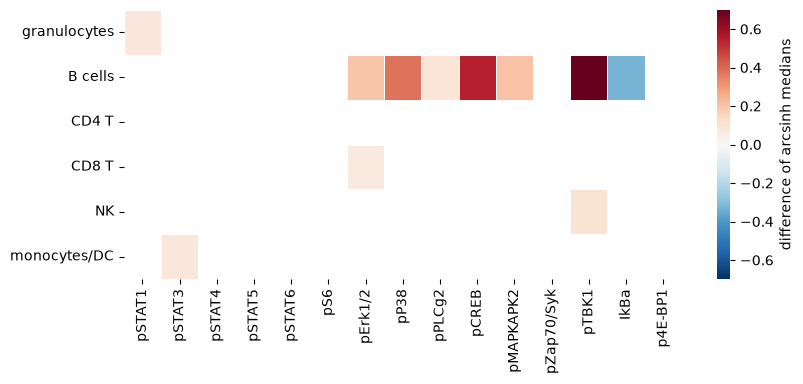

In [21]:
populations = results["population"].unique()
difference = results.pivot(index="population", columns="marker", values="difference").loc[populations, state_markers]
adj_p = results.pivot(index="population", columns="marker", values="adj_p_value").loc[populations, state_markers]
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.heatmap(
    difference.where(adj_p < 0.05),
    cmap="RdBu_r",
    center=0,
    vmin=-0.7,
    vmax=0.7,
    linewidths=0.5,
    cbar_kws={"label": "difference of arcsinh medians"},
    ax=ax,
)
ax.set(xlabel="", ylabel="");

All changes are small. The largest are in B cells: pTBK1 rises by about 0.7 on the arcsinh scale, pCREB by 0.5, pP38 by 0.4, and IkBa falls by 0.3. Lower IkBa is what one expects when the NF-kB pathway is activated, because IkBa is degraded then. All other significant differences are about 0.2 or smaller, and outside B cells about 0.1 or smaller. These results hold with FlowSOM seeds 0 and 1.

The plot shows, for the four largest B cell changes, the difference between the stimulated and the basal sample of each donor. The changes go in the same direction in all or all but one of the 14 donors, which fits the expectation that CD40L acts mainly on B cells:

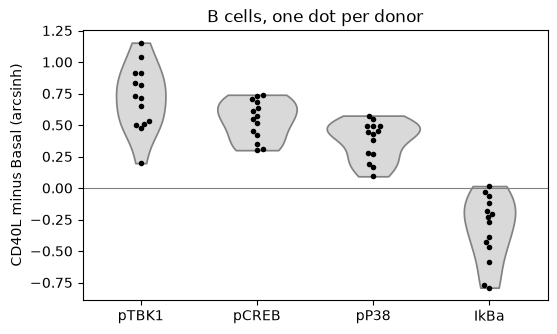

In [22]:
b_cells = pseudobulk[pseudobulk.obs["population"] == "B cells"]
b_medians = b_cells.to_df(layer="median").join(b_cells.obs[["condition", "donor"]])
b_medians = b_medians.pivot_table(index="donor", columns="condition", values=state_markers, observed=True)
b_change = b_medians.xs("CD40L", axis=1, level=1) - b_medians.xs("Basal", axis=1, level=1)
b_change = b_change[["pTBK1", "pCREB", "pP38", "IkBa"]].melt(var_name="marker", value_name="difference")

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.violinplot(b_change, x="marker", y="difference", inner=None, cut=0, color="0.85", ax=ax)
sns.swarmplot(b_change, x="marker", y="difference", color="black", size=4, ax=ax)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set(xlabel="", ylabel="CD40L minus Basal (arcsinh)", title="B cells, one dot per donor");

The same steps work for the GM-CSF samples in the archive, which you can try as an exercise: GM-CSF acts on myeloid cells rather than B cells.

## Session info

In [23]:
import session_info2

session_info2.session_info()

Package,Version
pandas,3.1.0
arviz-stats,1.3.3
mudata,0.4.1
matplotlib,3.11.2
anndata,0.13.4
pertpy,1.4.0
pooch,1.9.0 (v1.9.0)
scanpy,1.12.4
seaborn,0.13.2
statsmodels,0.15.0
